In [51]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from fredapi import Fred

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

FILES = ["Data_Nominal.csv"]
DATA = next((p for p in [Path("../data"), Path("data"), Path(".")]
             if all((p / f).exists() for f in FILES)), None)
if DATA is None:
    raise FileNotFoundError("Place Data_Nominal.csv in data/ or beside this notebook.")
OUT = DATA / "processed"
OUT.mkdir(parents=True, exist_ok=True)
START = "2015-01-01"
load_dotenv()
FRED_API_KEY = os.environ["FRED_API_KEY"]  # set in .env


## 1. Load and check Fiserv

In [52]:
def load(filename):
    df = pd.read_csv(DATA / filename)
    df.columns = (df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
                  .str.replace(" - ", "_", regex=False)
                  .str.replace(" ", "_", regex=False).str.lower())
    df = df.rename(columns={"sector_name": "sector", "sub-sector_name": "subsector"})
    df["date"] = pd.to_datetime(df["period"].astype(str), format="%Y%m%d")
    return df

nom = load("Data_Nominal.csv")
print(f"Nominal: {len(nom):,} rows")


Nominal: 173,646 rows


## 2. National FSBI

Nominal sales and transactions, adjusted and unadjusted. Sales / transactions × 100 is a ticket index proxy, not dollars per purchase.

In [53]:
us = (nom.query("geo == 'US' and sector == 'ALL' and subsector == 'ALL'")
      .set_index("date").sort_index())

if not us.index.is_unique:
    raise ValueError("Duplicate national FSBI months.")
us = us.reindex(pd.date_range(us.index.min(), us.index.max(), freq="MS", name="date"))

fiserv = us[["sales_index_sa", "transactional_index_sa",
             "sales_index_nsa", "transactional_index_nsa"]].rename(columns={
    "sales_index_sa": "sales_sa", "transactional_index_sa": "txn_sa",
    "sales_index_nsa": "sales_nsa", "transactional_index_nsa": "txn_nsa",
}).copy()
for adjustment in ["sa", "nsa"]:
    fiserv[f"ticket_index_{adjustment}"] = (
        fiserv[f"sales_{adjustment}"] / fiserv[f"txn_{adjustment}"] * 100
    )
fiserv = fiserv.add_prefix("fsbi_")
fiserv.tail(3).round(2)

,fsbi_sales_sa,fsbi_txn_sa,fsbi_sales_nsa,fsbi_txn_nsa,fsbi_ticket_index_sa,fsbi_ticket_index_nsa
date,,,,,,
2026-07-01,145.26,102.41,153.66,108.30,141.84,141.88
2026-08-01,144.94,102.06,149.78,107.54,142.01,139.28
2026-09-01,145.92,101.86,144.00,101.20,143.26,142.29


### 2.1 Breadth

Equal-weight shares with positive monthly SA growth, between 0 and 1. Sectors are fixed to those present in the first national month; geography uses the 50 states. A breadth value is missing unless every member has valid current and prior-month data. Zero growth is not positive. Counts below show coverage.

In [54]:
STATES = """AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD
MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT
VT VA WA WV WI WY""".split()

sector_rows = nom.loc[(nom.geo == "US") & (nom.sector != "ALL") &
                      (nom.subsector == "ALL") & nom.sector.notna()].copy()
sectors = sorted(sector_rows.loc[sector_rows.date == fiserv.index.min(), "sector"].unique())
state_rows = nom.loc[nom.geo.isin(STATES) & (nom.sector == "ALL") &
                     (nom.subsector == "ALL")].copy()

sector_rows["ticket_index"] = (
    sector_rows.sales_index_sa.where(sector_rows.sales_index_sa > 0)
    / sector_rows.transactional_index_sa.where(sector_rows.transactional_index_sa > 0)
)

def breadth_share(rows, category, members, value):
    if not members:
        raise ValueError("No categories available for breadth.")
    panel = rows.pivot(index="date", columns=category, values=value)
    panel = panel.reindex(index=fiserv.index, columns=members)
    change = panel.where(panel > 0).pct_change(fill_method=None)
    valid = change.notna().sum(axis=1)
    share = change.gt(0).sum(axis=1).div(valid.replace(0, np.nan))
    return share.where(valid == len(members)), valid

specs = {
    "fsbi_sector_sales_breadth": (sector_rows, "sector", sectors, "sales_index_sa"),
    "fsbi_sector_ticket_breadth": (sector_rows, "sector", sectors, "ticket_index"),
    "fsbi_state_sales_breadth": (state_rows, "geo", STATES, "sales_index_sa"),
}
breadth = pd.DataFrame(index=fiserv.index)
breadth_counts = pd.DataFrame(index=fiserv.index)
for name, args in specs.items():
    breadth[name], breadth_counts[name] = breadth_share(*args)

print(f"Breadth universe: {len(sectors)} sectors, {len(STATES)} states")
display(breadth.tail().round(3))
display(breadth_counts.tail())


Breadth universe: 13 sectors, 50 states


,fsbi_sector_sales_breadth,fsbi_sector_ticket_breadth,fsbi_state_sales_breadth
date,,,
2026-05-01,0.385,0.692,0.46
2026-06-01,0.769,0.538,0.78
2026-07-01,0.615,0.462,0.60
2026-08-01,0.385,0.462,0.36
2026-09-01,0.692,0.692,0.82


,fsbi_sector_sales_breadth,fsbi_sector_ticket_breadth,fsbi_state_sales_breadth
date,,,
2026-05-01,13,13,50
2026-06-01,13,13,50
2026-07-01,13,13,50
2026-08-01,13,13,50
2026-09-01,13,13,50


## 3. FRED

Fresh API download on every run. Oil uses monthly WTI (`WTISPLC`).

In [55]:
SERIES = {
    "CPIAUCSL": "cpi_sa", "CPIAUCNS": "cpi_nsa", "CPILFESL": "core_cpi_sa", "CPILFENS": "core_cpi_nsa",
    "PCEPI": "pce_price", "PCEPILFE": "core_pce_price",
    "CUSR0000SEFV": "cpi_food_away", "CUSR0000SETB01": "cpi_gasoline",
    "CUSR0000SAF11": "cpi_food_home", "CUSR0000SAH1": "cpi_shelter",
    "CPIAPPSL": "cpi_apparel", "CUSR0000SETA02": "cpi_used_cars",
    "RSAFS": "retail_sa", "RSAFSNA": "retail_nsa", "RSFSXMV": "retail_ex_auto",
    "PCE": "pce", "PCEC96": "real_pce", "PCEDG": "pce_durables",
    "PCEND": "pce_nondurables", "PCES": "pce_services",
    "DSPIC96": "real_income", "PSAVERT": "savings_rate",
    "UNRATE": "unemployment", "PAYEMS": "payrolls", "FEDFUNDS": "fed_funds",
    "DGS2": "treasury_2y", "DGS10": "treasury_10y", "T10YIE": "breakeven_10y",
    "UMCSENT": "sentiment", "MICH": "inflation_expect",
    "VIXCLS": "vix", "DTWEXBGS": "dollar", "WTISPLC": "oil",
    "DGS5": "dgs5", "DGS3MO": "dgs3mo",
    "INDPRO": "industrial_production", "HOUST": "housing_starts",
}

fred = Fred(api_key=FRED_API_KEY)
macro_raw = pd.DataFrame({
    name: fred.get_series(series_id, observation_start=START)
    for series_id, name in SERIES.items()
}).sort_index()
macro_raw.index = pd.to_datetime(macro_raw.index)
macro_raw = macro_raw.apply(pd.to_numeric, errors="raise")
if macro_raw.notna().sum().eq(0).any():
    raise ValueError("A FRED series has no observations.")
retrieved_at = pd.Timestamp.now(tz="UTC").isoformat()
print(f"Downloaded {macro_raw.shape[1]} series at {retrieved_at}")


Downloaded 37 series at 2026-10-23T17:18:48.667238+00:00


## 4. Cleveland Fed nowcasts

Daily MoM nowcasts plus the first-print actual and its release date. 
- `surprise`: first print − nowcast on the 6th of the following month. FSBI is out by then and it's when we'd trade.
- `surprise_final`: first print − last nowcast before release.

In [56]:
NOWCAST_URL = "https://www.clevelandfed.org/-/media/files/webcharts/inflationnowcasting/nowcast_month.json"
NOWCAST_SERIES = {"CPI Inflation": "cpi", "Core CPI Inflation": "core_cpi", "Core PCE Inflation": "core_pce"}
FSBI_DAY = 6  # 2026 FSBI releases landed on the 2nd–6th

rows = []
for chart in requests.get(NOWCAST_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=60).json():
    month = pd.Period(chart["chart"]["subcaption"], "M")
    days = [c["label"] for c in chart["categories"][0]["category"] if not c.get("vline")]
    for series in chart["dataset"]:
        for label, point in zip(days, series["data"]):
            if point.get("value"):
                m, d = map(int, label.split("/"))
                rows.append((month.to_timestamp(), pd.Timestamp(month.year + (m < month.month), m, d),
                             series["seriesname"], float(point["value"])))
raw_nowcast = pd.DataFrame(rows, columns=["date", "day", "series", "value"])

is_actual = raw_nowcast.series.str.startswith("Actual ")
actual = (raw_nowcast[is_actual].assign(series=lambda d: d.series.str.removeprefix("Actual "))
          .rename(columns={"day": "release", "value": "first_print"}))
daily = (raw_nowcast[~is_actual & raw_nowcast.series.isin(NOWCAST_SERIES)]
         .merge(actual, on=["date", "series"])
         .query("day < release").sort_values("day"))
on_fsbi_day = daily.day <= daily.date + pd.DateOffset(months=1, days=FSBI_DAY - 1)

by_month = daily.groupby(["date", "series"])
cleveland = pd.DataFrame({
    "nowcast_fsbi": daily[on_fsbi_day].groupby(["date", "series"]).value.last(),
    "nowcast_final": by_month.value.last(),
    "first_print": by_month.first_print.first(),
    "release": by_month.release.first(),
})
cleveland["surprise"] = cleveland.first_print - cleveland.nowcast_fsbi
cleveland["surprise_final"] = cleveland.first_print - cleveland.nowcast_final
cleveland = cleveland.unstack("series")
cleveland.columns = [f"clev_{NOWCAST_SERIES[s]}_{c}" for c, s in cleveland.columns]
cleveland.index.name = "date"
cleveland.loc["2019":].select_dtypes("number").describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
clev_cpi_nowcast_fsbi,92.0,0.299,0.241,-0.593,0.139,0.276,0.408,1.112
clev_core_cpi_nowcast_fsbi,92.0,0.282,0.121,0.099,0.190,0.257,0.360,0.539
clev_core_pce_nowcast_fsbi,92.0,0.244,0.099,0.079,0.146,0.232,0.305,0.440
clev_cpi_nowcast_final,92.0,0.298,0.242,-0.593,0.138,0.276,0.408,1.112
clev_core_cpi_nowcast_final,92.0,0.282,0.121,0.099,0.190,0.257,0.360,0.539
clev_core_pce_nowcast_final,92.0,0.244,0.148,-0.316,0.168,0.235,0.295,0.692
clev_cpi_first_print,92.0,0.308,0.321,-0.795,0.113,0.304,0.439,1.322
clev_core_cpi_first_print,92.0,0.285,0.206,-0.448,0.165,0.275,0.363,0.917
clev_core_pce_first_print,92.0,0.242,0.158,-0.393,0.153,0.246,0.335,0.664
clev_cpi_surprise,92.0,0.010,0.180,-0.371,-0.081,0.011,0.078,0.684


## 5. Monthly alignment

Daily financial series use monthly means; monthly series retain their reported observations. Missing values stay missing. A monthly date does not indicate when the value was published.

In [57]:
DAILY = ["treasury_2y", "treasury_10y", "dgs5", "dgs3mo",
         "breakeven_10y", "vix", "dollar"]
macro = macro_raw.resample("MS").last()
macro[DAILY] = macro_raw[DAILY].resample("MS").mean()
macro["dgs5_minus_dgs3mo"] = macro["dgs5"] - macro["dgs3mo"]
macro.index.name = "date"

coverage = pd.DataFrame({
    "first": macro.apply(lambda s: s.first_valid_index()),
    "last": macro.apply(lambda s: s.last_valid_index()),
    "interior_missing": macro.apply(
        lambda s: s.loc[s.first_valid_index():s.last_valid_index()].isna().sum()
        if s.notna().any() else len(s)
    ),
})
display(coverage)

,first,last,interior_missing
cpi_sa,2015-01-01,2026-09-01,1
cpi_nsa,2015-01-01,2026-09-01,1
core_cpi_sa,2015-01-01,2026-09-01,1
core_cpi_nsa,2015-01-01,2026-09-01,1
pce_price,2015-01-01,2026-08-01,0
core_pce_price,2015-01-01,2026-08-01,0
cpi_food_away,2015-01-01,2026-09-01,1
cpi_gasoline,2015-01-01,2026-09-01,0
cpi_food_home,2015-01-01,2026-09-01,1
cpi_shelter,2015-01-01,2026-09-01,1


## 6. Monthly growth

Keep monthly growth for three national FSBI signals and the three targets with Kalshi markets (CPI, core CPI, core PCE). Other series remain in levels. Breadth stays on its original 0–1 scale.

In [58]:
FSBI_SIGNALS = ["fsbi_sales_sa", "fsbi_txn_sa", "fsbi_ticket_index_sa"]
fsbi_levels = fiserv[FSBI_SIGNALS]
if ((fsbi_levels <= 0) & fsbi_levels.notna()).any().any():
    raise ValueError("FSBI log growth requires positive index values.")
fsbi_growth = (np.log(fsbi_levels).diff() * 100).add_suffix("_log_mom")

TARGET_SERIES = ["cpi_sa", "core_cpi_sa", "core_pce_price"]
target_growth = (
    macro[TARGET_SERIES].pct_change(fill_method=None) * 100
).add_suffix("_pct_mom")

## 6b. YoY targets and the NSA bridge

Kalshi and BLS quote headline and core CPI **YoY from the not-seasonally-adjusted index**, while the Cleveland nowcast and our MoM targets are seasonally adjusted. To get a YoY forecast from a MoM forecast we bridge:

`NSA_t = NSA_t-1 × (1 + MoM_sa/100) × exp(gap_t/100)`, then `YoY_t = NSA_t / NSA_t-12 − 1`

- `gap_t` is the NSA-minus-SA log MoM difference (the seasonal move). It is estimated from the same calendar month in the prior 3 years, so it is known on FSBI day. SA history is the latest FRED vintage, so seasonal-factor revisions leak slightly; the EDA below measures how much the bridge costs.
- NSA CPI is never revised, so the latest-vintage YoY is also the first print. Core PCE only exists SA and is revised, so its first-print YoY is rebuilt from ALFRED.
- YoY is not modelled directly. Since YoY_t ≈ YoY_t-1 + MoM_t − MoM_t-12, everything unknown about this month is in the MoM forecast; the rest is a base effect we already hold.
- Realised YoY is rounded to one decimal to match the published figure Kalshi settles on.

In [59]:
BRIDGE = {"cpi": ("cpi_nsa", "cpi_sa"), "core_cpi": ("core_cpi_nsa", "core_cpi_sa"),
          "core_pce": (None, "core_pce_price")}  # core PCE has no NSA series, so no seasonal gap

def first_print_yoy(series_id, start="2018-01-01"):
    """YoY % for each month using only the vintage in which that month was first published (ALFRED)."""
    v = fred.get_series_all_releases(series_id)
    v["value"] = pd.to_numeric(v["value"], errors="coerce")
    v["date"], v["realtime_start"] = pd.to_datetime(v["date"]), pd.to_datetime(v["realtime_start"])
    first = v.groupby("date").realtime_start.min().loc[start:]
    out = {}
    for d, released in first.items():
        base = d - pd.DateOffset(years=1)
        w = v[v.date.isin([d, base]) & (v.realtime_start <= released)]
        snap = w.sort_values("realtime_start").groupby("date").value.last().dropna()
        if d in snap.index and base in snap.index and snap[base] > 0:
            out[d] = round((snap[d] / snap[base] - 1) * 100, 1)
    return pd.Series(out, dtype=float)

nsa_yoy = macro[["cpi_nsa", "core_cpi_nsa"]].pct_change(12, fill_method=None) * 100
yoy_final = pd.DataFrame({
    "cpi_nsa_pct_yoy": nsa_yoy.cpi_nsa,
    "core_cpi_nsa_pct_yoy": nsa_yoy.core_cpi_nsa,
    "core_pce_price_pct_yoy": macro.core_pce_price.pct_change(12, fill_method=None) * 100,
})
yoy_first = pd.DataFrame({"cpi": nsa_yoy.cpi_nsa.round(1), "core_cpi": nsa_yoy.core_cpi_nsa.round(1),
                          "core_pce": first_print_yoy("PCEPILFE")})

def bridge_inputs(key):
    """Levels and expected seasonal gap needed to turn a month-t SA MoM forecast into YoY (all known on FSBI day)."""
    nsa, sa = BRIDGE[key]
    if nsa is None:
        level, gap = macro[sa], pd.Series(0.0, index=macro.index)
    else:
        level = macro[nsa]
        gap = (np.log(macro[nsa]).diff() - np.log(macro[sa]).diff()) * 100
    gap_hat = pd.concat([gap.shift(12 * n) for n in (1, 2, 3)], axis=1).mean(axis=1)
    return pd.DataFrame({f"{key}_bridge_prev": level.shift(1), f"{key}_bridge_ago12": level.shift(12),
                         f"{key}_bridge_gap": gap_hat})

bridge_cols = pd.concat([bridge_inputs(k) for k in BRIDGE], axis=1)

def bridge_yoy(mom, key, inputs=None):
    """SA MoM % forecast (Series by reference month) -> NSA YoY %. Same function is used in the models notebook."""
    b = (bridge_cols if inputs is None else inputs).reindex(mom.index)
    return ((b[f"{key}_bridge_prev"] * (1 + mom / 100) * np.exp(b[f"{key}_bridge_gap"] / 100))
            / b[f"{key}_bridge_ago12"] - 1) * 100

cleveland_yoy = pd.DataFrame(index=cleveland.index)
for k in BRIDGE:
    first = yoy_first[k].reindex(cleveland.index)
    nowcast_fsbi = bridge_yoy(cleveland[f"clev_{k}_nowcast_fsbi"], k)
    nowcast_final = bridge_yoy(cleveland[f"clev_{k}_nowcast_final"], k)
    cleveland_yoy[f"clev_{k}_yoy_nowcast_fsbi"] = nowcast_fsbi
    cleveland_yoy[f"clev_{k}_yoy_nowcast_final"] = nowcast_final
    cleveland_yoy[f"clev_{k}_yoy_first_print"] = first
    cleveland_yoy[f"clev_{k}_yoy_surprise"] = first - nowcast_fsbi
    cleveland_yoy[f"clev_{k}_yoy_surprise_final"] = first - nowcast_final

yoy_notes = {}
for k in BRIDGE:
    src = "ALFRED PCEPILFE, first-release vintage" if k == "core_pce" else "FRED " + ("CPIAUCNS" if k == "cpi" else "CPILFENS")
    yoy_notes.update({
        f"clev_{k}_yoy_nowcast_fsbi": "Cleveland MoM nowcast on FSBI day bridged to YoY (section 6b)",
        f"clev_{k}_yoy_nowcast_final": "Cleveland MoM nowcast before release bridged to YoY (section 6b)",
        f"clev_{k}_yoy_first_print": f"YoY % as first published, rounded to 0.1; {src}",
        f"clev_{k}_yoy_surprise": "first-print YoY - bridged FSBI-day nowcast YoY",
        f"clev_{k}_yoy_surprise_final": "first-print YoY - bridged final nowcast YoY",
        f"{k}_bridge_prev": "index level t-1 used by the YoY bridge",
        f"{k}_bridge_ago12": "index level t-12 used by the YoY bridge",
        f"{k}_bridge_gap": "expected NSA-SA MoM gap (pp): mean of same calendar month, prior 3 years",
    })

display(yoy_first.dropna(how="all").tail(4).round(1))
display(cleveland_yoy.filter(like="cpi_yoy").dropna().tail(4).round(2))

,cpi,core_cpi,core_pce
2026-06-01,3.5,2.6,3.3
2026-07-01,3.4,2.5,3.3
2026-08-01,3.4,2.4,3.0
2026-09-01,3.7,2.6,NaN


,clev_cpi_yoy_nowcast_fsbi,clev_cpi_yoy_nowcast_final,clev_cpi_yoy_first_print,clev_cpi_yoy_surprise,clev_cpi_yoy_surprise_final,clev_core_cpi_yoy_nowcast_fsbi,clev_core_cpi_yoy_nowcast_final,clev_core_cpi_yoy_first_print,clev_core_cpi_yoy_surprise,clev_core_cpi_yoy_surprise_final
date,,,,,,,,,,
2026-06-01,3.92,3.92,3.5,-0.42,-0.42,2.85,2.85,2.6,-0.25,-0.25
2026-07-01,3.42,3.42,3.4,-0.02,-0.02,2.52,2.52,2.5,-0.02,-0.02
2026-08-01,3.38,3.38,3.4,0.02,0.02,2.38,2.38,2.4,0.02,0.02
2026-09-01,3.60,3.60,3.7,0.10,0.10,2.39,2.39,2.6,0.21,0.21


## 7. Merge

Keep all FSBI months and leave missing values unchanged. Predictor lags are chosen when defining the forecast cutoff.

In [60]:
integrated = pd.concat([
    fiserv, breadth, macro, fsbi_growth, target_growth, yoy_final, cleveland, cleveland_yoy, bridge_cols
], axis=1).reindex(fiserv.index)
integrated.index.name = "date"
print(f"{len(integrated)} months × {len(integrated.columns)} columns")

93 months × 98 columns


C:\Users\liamf\AppData\Local\Temp\ipykernel_6076\534647240.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  integrated = pd.concat([


## 8. Save

In [61]:
base_columns = (list(fiserv.columns) + list(breadth.columns) + list(macro.columns) + list(cleveland.columns)
                + list(cleveland_yoy.columns) + list(bridge_cols.columns))
source_ids = {name: code for code, name in SERIES.items()}
source_ids["dgs5_minus_dgs3mo"] = "DGS5 - DGS3MO"
source_ids.update({c: "Cleveland Fed nowcast_month.json" for c in cleveland.columns})
source_ids.update({c: "derived (section 6b)" for c in list(cleveland_yoy.columns) + list(bridge_cols.columns)})

def describe(column):
    base = next(b for b in sorted(base_columns, key=len, reverse=True)
                if column == b or column.startswith(b + "_"))
    source = "Data_Nominal.csv" if base.startswith("fsbi_") else source_ids[base]
    transformation = column[len(base):].lstrip("_") or "level"
    if column in yoy_notes:
        transformation = yoy_notes[column]
    if base in breadth.columns:
        transformation = "share with positive monthly SA growth; full fixed-universe coverage required"
    if "ticket_index" in base:
        transformation = "sales index / transaction index * 100; " + transformation
    return source, base, transformation

metadata = [describe(col) for col in integrated.columns]
dictionary = pd.DataFrame({
    "column": integrated.columns,
    "source": [x[0] for x in metadata],
    "base_series": [x[1] for x in metadata],
    "transformation": [x[2] for x in metadata],
    "breadth_universe": [
        "; ".join(sectors) if x[1].startswith("fsbi_sector_") else
        "; ".join(STATES) if x[1] == "fsbi_state_sales_breadth" else ""
        for x in metadata
    ],
    "n_obs": integrated.notna().sum().values,
    "first": [s.first_valid_index() for _, s in integrated.items()],
    "last": [s.last_valid_index() for _, s in integrated.items()],
    "monthly_aggregation": [
        "mean of daily observations" if x[1] in DAILY else
        "difference of monthly mean yields" if x[1] == "dgs5_minus_dgs3mo" else
        "equal-weight category share" if x[1] in breadth.columns else
        "first release; nowcasts on the 6th of t+1 and last before release" if x[1] in cleveland.columns else
        "derived from monthly index levels and nowcasts (section 6b)" if x[1] in cleveland_yoy.columns or x[1] in bridge_cols.columns else
        "reported monthly observation" for x in metadata
    ],
    "fred_retrieved_at_utc": [retrieved_at if x[1] in macro.columns else "" for x in metadata],
    "availability": "reference month; historical availability not reconstructed",
})
integrated.to_csv(OUT / "integrated_monthly.csv")
dictionary.to_csv(OUT / "data_dictionary.csv", index=False)
print("Saved integrated_monthly.csv and data_dictionary.csv")

Saved integrated_monthly.csv and data_dictionary.csv


# EDA

The last 18 months are held out for model evaluation; nothing below touches them. COVID months (Mar 2020 – Jun 2021) are flagged separately.

Targets are the three with Kalshi markets: CPI MoM, core CPI MoM, core PCE MoM.


In [62]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf

SIGNALS = ["fsbi_sales_sa_log_mom", "fsbi_txn_sa_log_mom", "fsbi_ticket_index_sa_log_mom",
           "fsbi_sector_sales_breadth", "fsbi_sector_ticket_breadth", "fsbi_state_sales_breadth"]
KEYS = ["cpi", "core_cpi", "core_pce"]
TARGETS = ["cpi_sa_pct_mom", "core_cpi_sa_pct_mom", "core_pce_price_pct_mom"]
SURPRISES = [f"clev_{k}_surprise" for k in KEYS]

HOLDOUT_START = pd.Timestamp("2025-03-01")  # last 18 months of the Aug 2026 file
df = integrated.loc[:HOLDOUT_START - pd.DateOffset(months=1)]
covid = df.index.to_series().between("2020-03-01", "2021-06-01")
clean = df[~covid]

short = lambda c: c.replace("fsbi_", "").replace("clev_", "").replace("_log_mom", "").replace("_pct_mom", "")
rmse = lambda e: np.sqrt(np.mean(np.square(e)))
print(f"EDA: {df.index[0]:%Y-%m} to {df.index[-1]:%Y-%m} ({len(df)} months, {len(clean)} ex-COVID)")
print(f"Holdout: {HOLDOUT_START:%Y-%m} to {integrated.index[-1]:%Y-%m}")

EDA: 2019-01 to 2025-02 (74 months, 58 ex-COVID)
Holdout: 2025-03 to 2026-09


## 9. Summary stats

In [63]:
df[SIGNALS + TARGETS + SURPRISES].describe().T.rename(index=short).round(2)

,count,mean,std,min,25%,50%,75%,max
sales_sa,73.0,0.51,3.45,-18.36,-0.21,0.42,1.15,13.60
txn_sa,73.0,0.06,3.94,-24.22,-0.40,0.27,0.65,13.35
ticket_index_sa,73.0,0.45,1.13,-2.38,-0.17,0.25,0.72,5.86
sector_sales_breadth,73.0,0.66,0.27,0.00,0.46,0.77,0.92,1.00
sector_ticket_breadth,73.0,0.55,0.17,0.08,0.46,0.54,0.69,0.92
state_sales_breadth,73.0,0.61,0.27,0.00,0.42,0.68,0.82,1.00
cpi_sa,74.0,0.32,0.31,-0.79,0.16,0.28,0.45,1.26
core_cpi_sa,74.0,0.30,0.21,-0.49,0.19,0.27,0.40,0.81
core_pce_price,74.0,0.27,0.16,-0.32,0.15,0.26,0.36,0.62
cpi_surprise,74.0,0.01,0.19,-0.37,-0.10,0.01,0.08,0.68


## 10. Trends

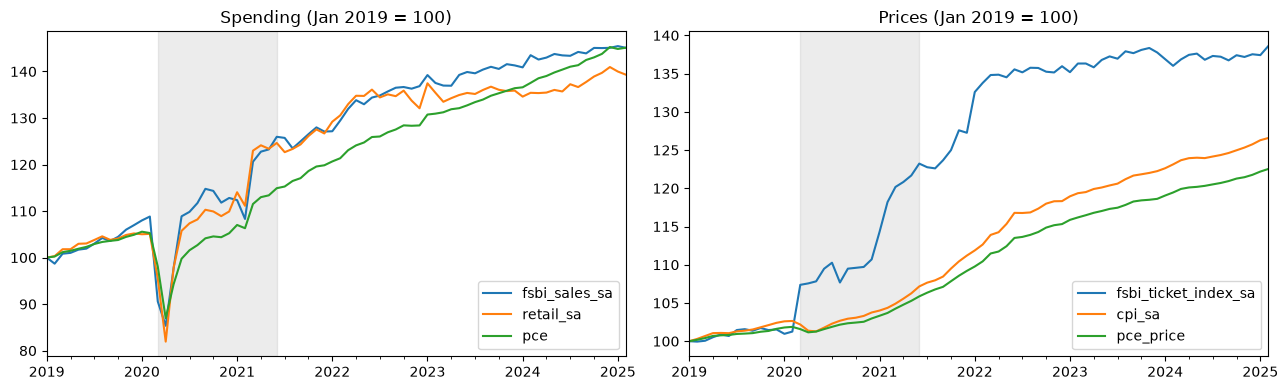

In [64]:
levels = df[["fsbi_sales_sa", "retail_sa", "pce", "fsbi_ticket_index_sa", "cpi_sa", "pce_price"]]
levels = levels / levels.iloc[0] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cols, title in zip(axes, [levels.columns[:3], levels.columns[3:]], ["Spending", "Prices"]):
    levels[cols].plot(ax=ax, title=f"{title} (Jan 2019 = 100)", lw=1.5)
    ax.axvspan("2020-03-01", "2021-06-01", color="grey", alpha=0.15)
    ax.set_xlabel("")
plt.tight_layout()

## 11. Seasonality

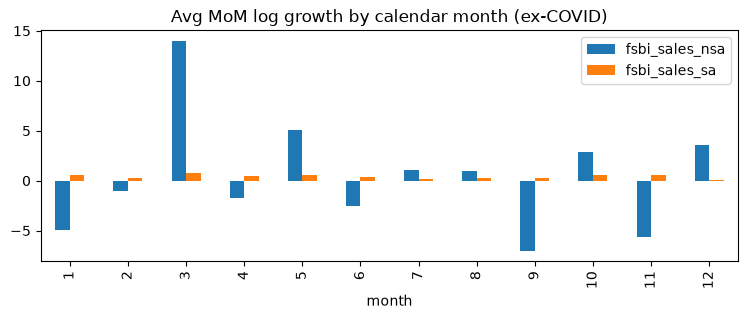

In [65]:
mom = np.log(df[["fsbi_sales_nsa", "fsbi_sales_sa"]]).diff()[~covid] * 100
mom.groupby(mom.index.month).mean().plot.bar(figsize=(9, 3), title="Avg MoM log growth by calendar month (ex-COVID)")
plt.xlabel("month");

SA removes the calendar pattern, so the SA series are what we use from here on.

## 12. How good is the Cleveland nowcast?

RMSE against the first print, ex-COVID. Nowcast on FSBI day (the 6th) vs the last one before release. AR(2) is fit in-sample, so it's flattered.

In [66]:
nowcast_rmse = {}
for k in KEYS:
    y = df[f"clev_{k}_first_print"]
    lags = pd.concat([y.shift(1), y.shift(2)], axis=1)
    ok = ~covid & y.notna() & lags.notna().all(axis=1)
    ar = sm.OLS(y[ok], sm.add_constant(lags[ok])).fit()
    nowcast_rmse[k] = {"nowcast_fsbi_day": rmse(df.loc[ok, f"clev_{k}_surprise"]),
                       "nowcast_final": rmse(df.loc[ok, f"clev_{k}_surprise_final"]),
                       "ar2": rmse(ar.resid), "last_month": rmse((y - y.shift(1))[ok])}
pd.DataFrame(nowcast_rmse).T.round(3)

,nowcast_fsbi_day,nowcast_final,ar2,last_month
cpi,0.158,0.160,0.270,0.328
core_cpi,0.127,0.127,0.126,0.154
core_pce,0.121,0.094,0.123,0.151


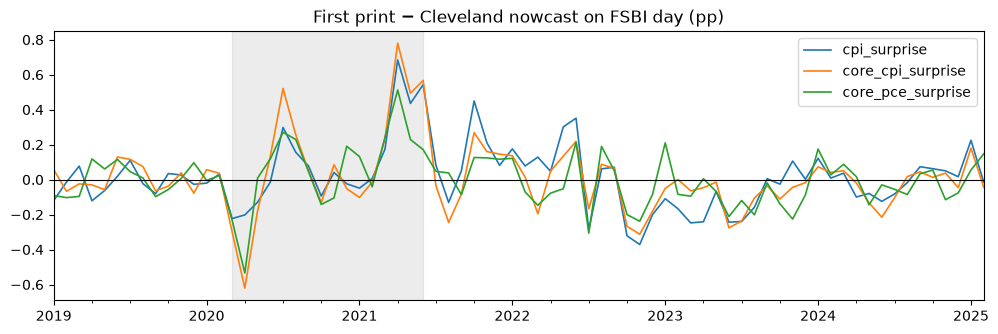

In [67]:
ax = df[SURPRISES].rename(columns=short).plot(figsize=(12, 3.5), lw=1.2, title="First print − Cleveland nowcast on FSBI day (pp)")
ax.axvspan("2020-03-01", "2021-06-01", color="grey", alpha=0.15)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("");

## 13. Correlations (ex-COVID)

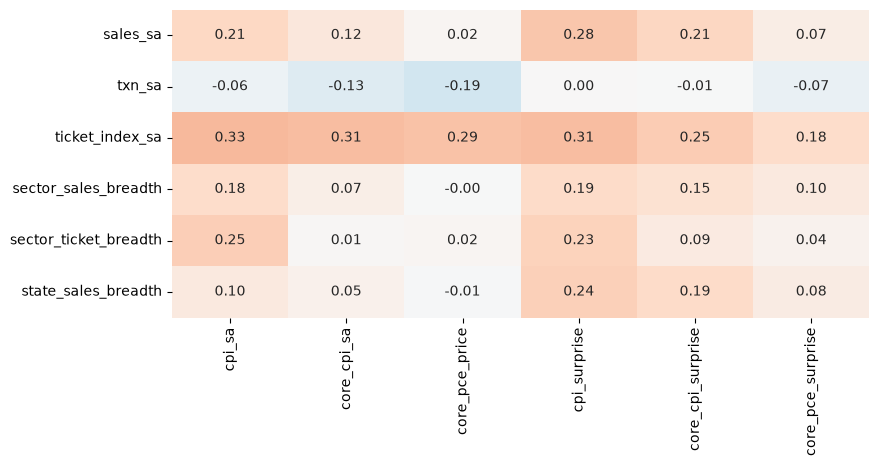

In [68]:
c = clean[SIGNALS + TARGETS + SURPRISES].corr().loc[SIGNALS, TARGETS + SURPRISES]
plt.figure(figsize=(9, 4))
sns.heatmap(c.rename(index=short, columns=short), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False);

Ticket growth is the most consistent signal for CPI and core CPI surprises. Against the FSBI-day nowcast, core PCE picks up a weak ticket correlation (0.19).

## 14. Persistence of the surprise

In [69]:
post = df.loc["2021-07-01":, SURPRISES]  # contiguous post-COVID block
pd.DataFrame({short(s): acf(post[s].dropna(), nlags=12)[[1, 2, 3, 12]] for s in SURPRISES},
             index=["lag1", "lag2", "lag3", "lag12"]).T.round(2)

,lag1,lag2,lag3,lag12
cpi_surprise,0.47,0.27,0.42,-0.26
core_cpi_surprise,0.39,0.00,-0.05,-0.16
core_pce_surprise,0.06,-0.09,0.01,0.10


Headline and core CPI surprises carry over month to month, so last month's surprise is the baseline to beat, not zero. Core PCE surprises don't.

## 15. Does FSBI predict the surprise beyond last month's surprise?

Baseline: s_t ~ s_t−1. Then add the same-month FSBI signal. Surprise is vs the nowcast on FSBI day, when we'd trade. Pre-holdout, ex-COVID.
- `p`: HAC p-value on the FSBI term
- `wf`: walk-forward RMSE, baseline + FSBI vs baseline. Refit each month, forecast the next, starting after 24 months.
- `wf_vs_nowcast`: same, but vs just trusting the FSBI-day nowcast (surprise = 0)

Below 1 = FSBI helps.

In [ ]:
def add_test(y, x, controls=(), min_train=24):
    """Does x improve on y_t ~ y_t-1 + controls? In-sample HAC p-value and walk-forward RMSE ratios."""
    Z = pd.concat([df[y].rename("y"), df[y].shift(1).rename("y1"), df[list(controls)],
                   df[x].rename("x")], axis=1)[~covid].dropna()
    base_cols = ["y1", *controls]
    fit = lambda d, cols: sm.OLS(d.y, sm.add_constant(d[cols])).fit()
    p = fit(Z, base_cols + ["x"]).get_robustcov_results(cov_type="HAC", maxlags=3).pvalues[-1]

    err = {"base": [], "full": []}
    for t in range(min_train, len(Z)):
        train, test = Z.iloc[:t], Z.iloc[[t]]
        for name, cols in [("base", base_cols), ("full", base_cols + ["x"])]:
            pred = fit(train, cols).predict(sm.add_constant(test[cols], has_constant="add")).iloc[0]
            err[name].append(test.y.iloc[0] - pred)
    nowcast = rmse(Z.y.iloc[min_train:])
    return {"p": p, "wf": rmse(err["full"]) / rmse(err["base"]),
            "wf_vs_nowcast": rmse(err["full"]) / nowcast, "base_vs_nowcast": rmse(err["base"]) / nowcast,
            "rmse_nowcast": nowcast, "rmse_base": rmse(err["base"]), "rmse_full": rmse(err["full"])}

def plot_tests(results, index):
    fig, axes = plt.subplots(1, 3, figsize=(15, 0.45 * results[index].nunique() + 1.5), sharey=True)
    for ax, col in zip(axes, ["p", "wf", "wf_vs_nowcast"]):
        kw = dict(cmap="Greens_r", vmin=0, vmax=0.2) if col == "p" else dict(cmap="RdYlGn_r", center=1, vmin=0.85, vmax=1.15)
        sns.heatmap(results.pivot(index=index, columns="surprise", values=col), annot=True, fmt=".2f", cbar=False, ax=ax, **kw)
        ax.set_title(col)
    plt.tight_layout()

results = pd.DataFrame([{"surprise": short(y), "signal": short(x), **add_test(y, x)}
                        for y in SURPRISES for x in SIGNALS])
results.groupby("surprise")["base_vs_nowcast"].first().round(3)

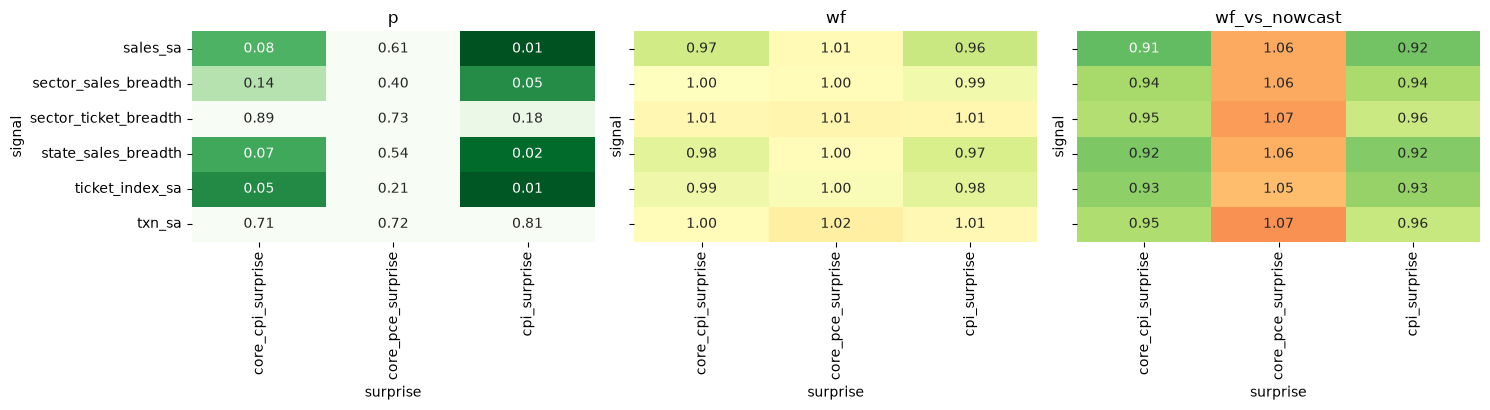

In [ ]:
plot_tests(results, "signal")

In [ ]:
# walk-forward RMSE (pp): raw nowcast, + last month's surprise, + FSBI
(results.assign(fsbi_gain_pct=lambda r: (1 - r.rmse_full / r.rmse_base) * 100,
                total_gain_pct=lambda r: (1 - r.rmse_full / r.rmse_nowcast) * 100)
        .set_index(["surprise", "signal"])
        [["rmse_nowcast", "rmse_base", "rmse_full", "fsbi_gain_pct", "total_gain_pct"]].round(3))

rmse_nowcast  rmse_base  rmse_full  fsbi_gain_pct  total_gain_pct
surprise          signal                                                                                  
cpi_surprise      sales_sa                      0.168      0.160      0.154          3.935           8.418
                  txn_sa                        0.168      0.160      0.161         -0.596           4.099
                  ticket_index_sa               0.168      0.160      0.157          2.178           6.743
                  sector_sales_breadth          0.168      0.160      0.158          1.105           5.720
                  sector_ticket_breadth         0.168      0.160      0.162         -0.899           3.809
                  state_sales_breadth           0.168      0.160      0.155          3.025           7.550
core_cpi_surprise sales_sa                      0.133      0.125      0.121          3.441           9.097
                  txn_sa                        0.133      0.125      0.126         -0.395           5.486
                  ticket_index_sa               0.133      0.125      0.124          1.259           7.043
                  sector_sales_breadth          0.133      0.125      0.125          0.002           5.859
                  sector_ticket_breadth         0.133      0.125      0.126         -0.736           5.164
                  state_sales_breadth           0.133      0.125      0.122          2.123           7.856
core_pce_surprise sales_sa                      0.140      0.147      0.148         -0.502          -6.184
                  txn_sa                        0.140      0.147      0.150         -1.558          -7.299
                  ticket_index_sa               0.140      0.147      0.147          0.477          -5.150
                  sector_sales_breadth          0.140      0.147      0.148         -0.424          -6.102
                  sector_ticket_breadth         0.140      0.147      0.149         -1.025          -6.737
                  state_sales_breadth           0.140      0.147      0.148         -0.268          -5.937

## 16. Macro indicators alongside FSBI

Candidates are limited to what's public by FSBI day and isn't already in the Cleveland model (oil, gasoline, lagged CPI/PCE). CPI components are last month's (this month's come out with CPI). Baseline is now s_t−1 + ticket growth; each candidate is added one at a time.

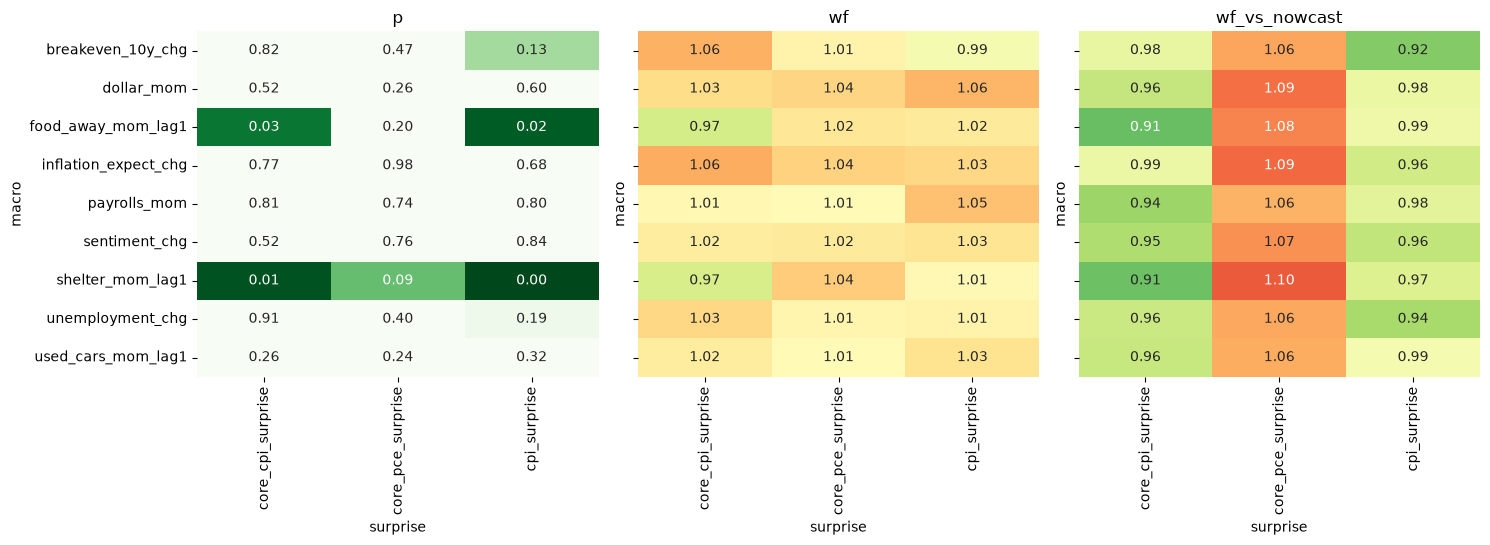

In [ ]:
FSBI_BASE = "fsbi_ticket_index_sa_log_mom"
mom = lambda s: s.pct_change(fill_method=None) * 100
candidates = pd.DataFrame({
    "shelter_mom_lag1": mom(integrated.cpi_shelter).shift(1),
    "used_cars_mom_lag1": mom(integrated.cpi_used_cars).shift(1),
    "food_away_mom_lag1": mom(integrated.cpi_food_away).shift(1),
    "inflation_expect_chg": integrated.inflation_expect.diff(),
    "breakeven_10y_chg": integrated.breakeven_10y.diff(),
    "dollar_mom": mom(integrated.dollar),
    "payrolls_mom": mom(integrated.payrolls),
    "unemployment_chg": integrated.unemployment.diff(),
    "sentiment_chg": integrated.sentiment.diff(),
})
df = df.join(candidates)

macro_results = pd.DataFrame([{"surprise": short(y), "macro": m, **add_test(y, m, controls=[FSBI_BASE])}
                              for y in SURPRISES for m in candidates])
plot_tests(macro_results, "macro")

Only last month's shelter and food-away-from-home inflation show anything. Both are significant in-sample for CPI and core CPI, but walk-forward they only help core CPI (~3%). 

## 17. YoY targets

Same pre-holdout, ex-COVID sample. Four numbers per target (pp):
- `nowcast_fsbi_day` / `nowcast_final`: RMSE of the bridged Cleveland nowcast against the published YoY
- `last_yoy`: RMSE of simply carrying last month's YoY forward
- `bridge_floor`: RMSE from bridging the *realised* MoM first print. This is the error the bridge adds even with a perfect MoM forecast, so no YoY forecast can beat it by much.
- `corr_with_mom_surprise`: how closely the YoY surprise tracks the MoM surprise

In [ ]:
YOY_FP = [f"clev_{k}_yoy_first_print" for k in KEYS]
YOY_SURP = [f"clev_{k}_yoy_surprise" for k in KEYS]
display(df[YOY_FP + YOY_SURP].describe().T.rename(index=short).round(2))

rows = {}
for k in KEYS:
    y, s = df[f"clev_{k}_yoy_first_print"], df[f"clev_{k}_yoy_surprise"]
    ok = ~covid & y.notna() & s.notna()
    bridged = bridge_yoy(df[f"clev_{k}_first_print"], k)
    rows[k] = {"n": int(ok.sum()),
               "corr_with_mom_surprise": s[ok].corr(df.loc[ok, f"clev_{k}_surprise"]),
               "nowcast_fsbi_day": rmse(s[ok]),
               "nowcast_final": rmse(df.loc[ok, f"clev_{k}_yoy_surprise_final"].dropna()),
               "last_yoy": rmse((y - y.shift(1))[ok].dropna()),
               "bridge_floor": rmse((bridged - y)[ok].dropna())}
pd.DataFrame(rows).T.round(3)

,count,mean,std,min,25%,50%,75%,max
cpi_yoy_first_print,74.0,3.79,2.42,0.10,1.80,3.05,5.40,9.10
core_cpi_yoy_first_print,74.0,3.63,1.63,1.20,2.20,3.35,4.88,6.60
core_pce_yoy_first_print,74.0,2.99,1.35,0.90,1.60,2.80,4.35,5.40
cpi_yoy_surprise,74.0,0.02,0.20,-0.34,-0.09,0.01,0.11,0.66
core_cpi_yoy_surprise,74.0,0.01,0.20,-0.70,-0.10,-0.02,0.08,0.72
core_pce_yoy_surprise,74.0,-0.15,0.24,-0.71,-0.26,-0.11,-0.01,0.48


,n,corr_with_mom_surprise,nowcast_fsbi_day,nowcast_final,last_yoy,bridge_floor
cpi,58.0,0.904,0.162,0.165,0.383,0.072
core_cpi,58.0,0.883,0.130,0.130,0.225,0.063
core_pce,58.0,0.507,0.289,0.268,0.202,0.254


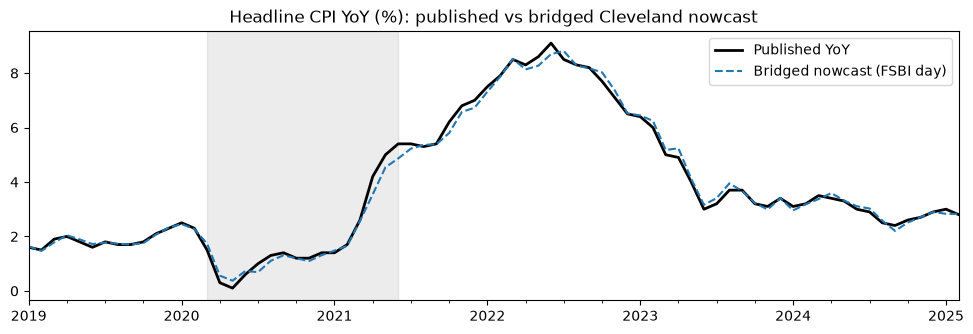

In [ ]:
fig, ax = plt.subplots(figsize=(12, 3.5))
df["clev_cpi_yoy_first_print"].plot(ax=ax, color="k", lw=2, label="Published YoY")
df["clev_cpi_yoy_nowcast_fsbi"].plot(ax=ax, color="tab:blue", ls="--", label="Bridged nowcast (FSBI day)")
ax.axvspan("2020-03-01", "2021-06-01", color="grey", alpha=0.15)
ax.set_title("Headline CPI YoY (%): published vs bridged Cleveland nowcast"); ax.set_xlabel(""); ax.legend();